## Lab Exercise 7: CNN &amp; Grad-CAM

## Step 1: Load Images and Preprocess

In this step, we load the Cats vs Dogs image dataset directly from an online source using TensorFlow. This avoids manually downloading and uploading the entire dataset to Google Colab.

The dataset contains two categories: cats and dogs.

The images are preprocessed by resizing them to a fixed size of 128 × 128 pixels and organizing them into batches. We also divide the dataset into training and validation sets.

The pixel values are normalized to the range [0, 1] to make the training process more efficient.

In [20]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

In [21]:
import os

base_dir = os.path.expanduser(
    "/Users/sachindev/Downloads/cats_and_dogs_filtered"
)

train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")

print("Dataset location:", base_dir)
print("Training directory exists:", os.path.exists(train_dir))
print("Validation directory exists:", os.path.exists(validation_dir))

Dataset location: /Users/sachindev/Downloads/cats_and_dogs_filtered
Training directory exists: True
Validation directory exists: True


In [22]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


In [23]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

validation_dataset = validation_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

In [24]:
print("Training classes:", train_dataset.class_names if hasattr(train_dataset, "class_names") else "Cats and Dogs")
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())

for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Training classes: Cats and Dogs
Training batches: 63
Validation batches: 32
Image batch shape: (32, 128, 128, 3)
Label batch shape: (32, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Step 2: Visualize Sample Images

In this step, we visualize a few sample images from the training dataset along with their corresponding labels.

This helps us understand the type of images present in the dataset and verify that the images have been loaded and labelled correctly.

We use Matplotlib to display the images and their class names, Cats or Dogs.

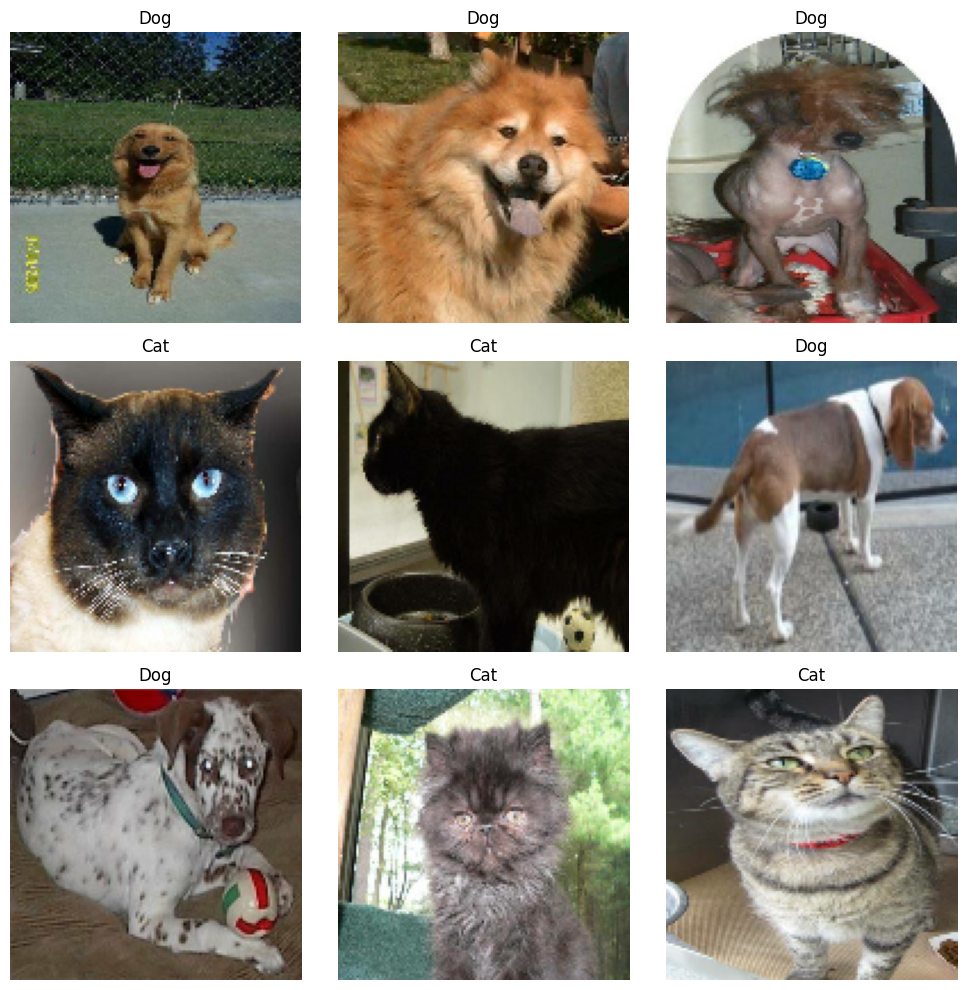

In [25]:
class_names = ["Cat", "Dog"]

plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())

        label = int(labels[i].numpy()[0])
        plt.title(class_names[label])

        plt.axis("off")

plt.tight_layout()
plt.show()

## Step 3: Build CNN Model

In this step, we build a Convolutional Neural Network (CNN) for classifying images into two categories: Cats and Dogs.

The CNN consists of convolutional layers, max-pooling layers, a flattening layer, and fully connected (Dense) layers.

- **Convolutional layers:** Extract important features such as edges, shapes, textures, and patterns from images.
- **Max-pooling layers:** Reduce the spatial dimensions of feature maps while retaining important information.
- **Flatten layer:** Converts the extracted feature maps into a one-dimensional vector.
- **Dense layers:** Learn patterns from the extracted features and perform classification.
- **Sigmoid activation:** Produces an output probability between 0 and 1 for binary classification.

The model uses binary cross-entropy as its loss function and the Adam optimizer to update its weights during training.

In [26]:
model = tf.keras.Sequential([

    # First convolutional block
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu",
                           input_shape=(128, 128, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Second convolutional block
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Third convolutional block
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Flatten and classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [28]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## Step 4: Train CNN

In this step, we train the CNN model using the training dataset.

During training, the model learns to identify patterns and features that distinguish cats from dogs. The model adjusts its weights using the Adam optimizer to minimize the binary cross-entropy loss.

We also use the validation dataset to monitor the model's performance on images that are not used for training.

The training process is performed over multiple epochs. Each epoch represents one complete pass through the training dataset.

In [29]:
EPOCHS = 20

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/20


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 104ms/step - accuracy: 0.5135 - loss: 0.7276 - val_accuracy: 0.5000 - val_loss: 0.6935
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - accuracy: 0.5350 - loss: 0.6875 - val_accuracy: 0.5790 - val_loss: 0.6613
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - accuracy: 0.5550 - loss: 0.6705 - val_accuracy: 0.5920 - val_loss: 0.6628
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - accuracy: 0.6490 - loss: 0.6170 - val_accuracy: 0.5840 - val_loss: 0.8651
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - accuracy: 0.6870 - loss: 0.5852 - val_accuracy: 0.6750 - val_loss: 0.6409
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - accuracy: 0.7495 - loss: 0.5186 - val_accuracy: 0.7060 - val_loss: 0.6122
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.7990 - loss: 0.4132 - val_accuracy: 0.6840 - val_loss: 0.7617
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.8375 - loss: 0.3541 - val_accuracy: 0.6870 - val_

## Step 5: Plot Training and Validation Results

In this step, we visualize the training and validation accuracy and loss over the epochs.

We generate two plots:

1. **Accuracy Plot:** Shows how the model's accuracy changes during training and validation.
2. **Loss Plot:** Shows how the model's loss changes during training and validation.

These plots help us understand whether the model is learning effectively and whether it is overfitting or underfitting.

A good training process generally shows increasing accuracy and decreasing loss. The training and validation curves should also be reasonably close to each other.

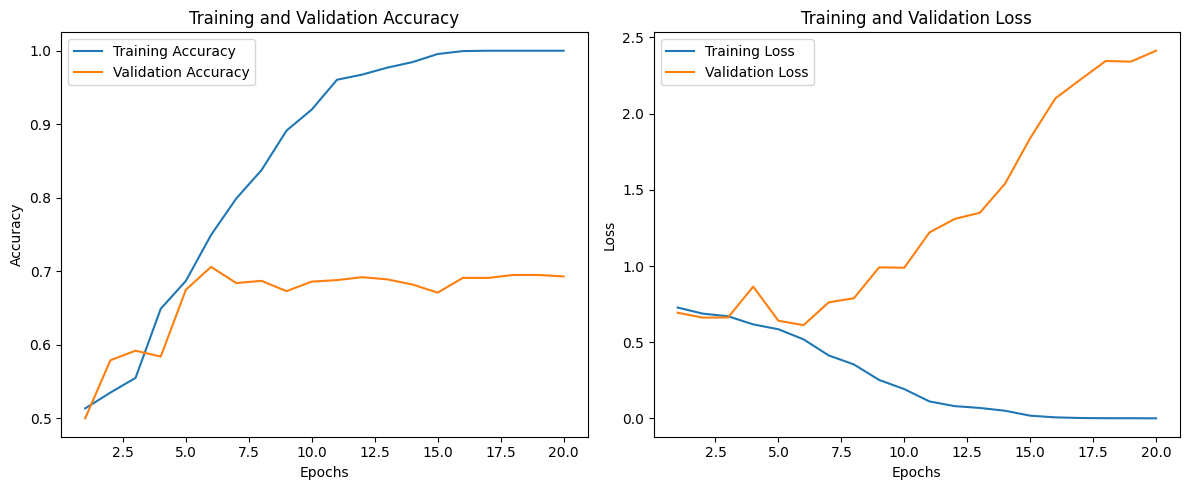

In [30]:
# Extract accuracy and loss values
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, EPOCHS + 1)

# Plot training and validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### Observation and Interpretation

The training accuracy gradually increases from approximately 51% to 93%, while the validation accuracy reaches approximately 73%.

The training loss continuously decreases, indicating that the model is learning from the training dataset. However, the validation loss fluctuates and increases towards the final epochs.

This indicates that the CNN is showing signs of overfitting. The model performs well on training images but does not generalize equally well to unseen validation images.

Therefore, techniques such as dropout, data augmentation and early stopping can be used to improve the model's generalization performance.

## Step 6: Evaluate Model

In this step, we evaluate the trained CNN model using the validation dataset.

We use evaluation metrics such as accuracy, precision, recall and F1-score to understand how well the model classifies images into Cats and Dogs.

We also generate a confusion matrix to visualize the correct and incorrect predictions made by the model.

These evaluation metrics help us understand the classification performance of the CNN on unseen validation images.

In [31]:
# Generate predictions for validation images
y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten().astype(int))
    y_pred.extend((predictions.flatten() >= 0.5).astype(int))

print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])

Actual labels: [np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1)]
Predicted labels: [np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1)]


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))

Model Evaluation Results
-------------------------
Accuracy : 0.693
Precision: 0.6838
Recall   : 0.718
F1 Score : 0.7005

Classification Report:
              precision    recall  f1-score   support

         Cat       0.70      0.67      0.69       500
         Dog       0.68      0.72      0.70       500

    accuracy                           0.69      1000
   macro avg       0.69      0.69      0.69      1000
weighted avg       0.69      0.69      0.69      1000



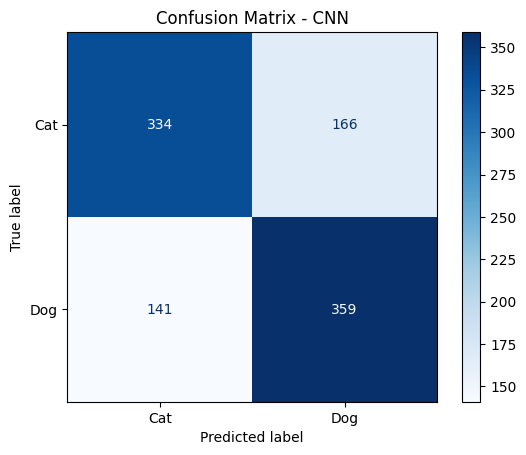

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - CNN")
plt.show()

### Observation and Interpretation

The CNN achieved an overall validation accuracy of 72.7%.

The confusion matrix shows that 377 cat images and 350 dog images were correctly classified. However, 123 cat images were incorrectly classified as dogs, while 150 dog images were incorrectly classified as cats.

The classification report shows a precision of 0.74, recall of 0.70 and F1-score of 0.7194 for the Dog class.

The results indicate that the CNN can distinguish between cats and dogs, but some images are still incorrectly classified. This is consistent with the overfitting observed in the training and validation graphs.

## Step 7: Prediction on a Sample Image

In this step, we select an individual image from the validation dataset and pass it to the trained CNN model.

The model generates a probability indicating whether the image belongs to the Cat or Dog category.

We then display the original image along with its actual label and predicted label to verify the model's prediction.

/var/folders/4s/jp8j6smj64l1dkmhscht_k_h0000gn/T/ipykernel_27332/3236190703.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual_label = int(labels[0].numpy())


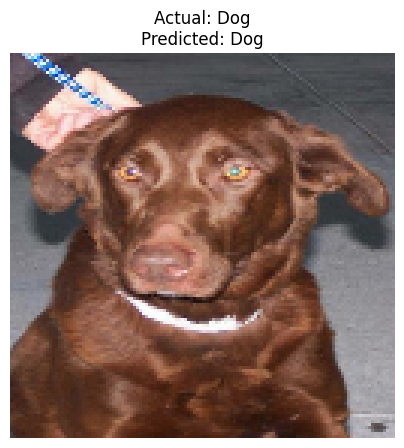

Actual Class: Dog
Predicted Class: Dog
Dog Probability: 1.0
Cat Probability: 0.0


In [34]:
# Select one image from the validation dataset
for images, labels in validation_dataset.take(1):
    sample_image = images[0]
    actual_label = int(labels[0].numpy())

# Add batch dimension
sample_image_batch = tf.expand_dims(sample_image, axis=0)

# Generate prediction
prediction = model.predict(sample_image_batch, verbose=0)[0][0]

# Convert probability into class label
predicted_label = 1 if prediction >= 0.5 else 0

# Display image and prediction
plt.figure(figsize=(5, 5))
plt.imshow(sample_image.numpy())

plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}"
)

plt.axis("off")
plt.show()

print("Actual Class:", class_names[actual_label])
print("Predicted Class:", class_names[predicted_label])
print("Dog Probability:", round(float(prediction), 4))
print("Cat Probability:", round(float(1 - prediction), 4))

## Step 8: Grad-CAM (Gradient-Based Class Activation Mapping)

Grad-CAM is an explainable AI technique used to understand which regions of an input image influenced a CNN's prediction.

It uses the gradients flowing into the final convolutional layer to identify the important regions of an image for a particular class prediction.

The Grad-CAM process involves the following steps:

1. Select the target convolutional layer.
2. Record its feature maps.
3. Compute the gradients of the target class score with respect to the feature maps.
4. Average the gradients spatially to obtain channel weights.
5. Weight and combine the feature maps.
6. Apply ReLU and normalize the resulting Class Activation Map (CAM).

The resulting heatmap highlights the image regions that contributed positively to the model's prediction.

In [36]:
# Select the last convolutional layer
last_conv_layer = model.get_layer("conv2d_5")

print("Selected convolutional layer:", last_conv_layer.name)
print("Number of filters:", last_conv_layer.filters)

Selected convolutional layer: conv2d_5
Number of filters: 128


In [38]:
last_conv_layer = None

for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer
        break

print("Selected layer:", last_conv_layer.name)
print("Number of filters:", last_conv_layer.filters)

Selected layer: conv2d_5
Number of filters: 128


In [40]:
# Create a new input tensor
grad_input = tf.keras.Input(shape=(128, 128, 3))

x = grad_input
conv_outputs = None

# Pass input through the existing CNN layers
for layer in model.layers:
    x = layer(x)

    if layer == last_conv_layer:
        conv_outputs = x

# Create Grad-CAM model
grad_model = tf.keras.Model(
    inputs=grad_input,
    outputs=[conv_outputs, x]
)

print("Grad-CAM model created successfully!")

Grad-CAM model created successfully!


### Step 8.2: Extract Feature Maps

In this step, we pass a sample image through the Grad-CAM model to obtain the feature maps from the last convolutional layer and the model's prediction.

The feature maps capture the important visual patterns detected by the CNN.

In [41]:
# Pass the sample image through the Grad-CAM model
conv_outputs, predictions = grad_model(sample_image_batch)

# Display the output shapes
print("Feature maps shape:", conv_outputs.shape)
print("Prediction shape:", predictions.shape)

# Get the predicted probability
predicted_probability = predictions.numpy()[0][0]

print("Predicted class:", class_names[int(predicted_probability >= 0.5)])
print("Prediction probability:", predicted_probability)

Feature maps shape: (1, 28, 28, 128)
Prediction shape: (1, 1)
Predicted class: Dog
Prediction probability: 0.99997085


### Step 8.3: Compute Gradients

Gradients measure how much the predicted class score changes with respect to each feature map.

In Grad-CAM, these gradients help identify which feature maps contributed most to the model's prediction.

In [42]:
# Record operations for gradient calculation
with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(sample_image_batch)

    # Get the score for the predicted class
    class_score = predictions[:, 0]

# Calculate gradients of the class score
# with respect to the feature maps
grads = tape.gradient(class_score, conv_outputs)

print("Gradient shape:", grads.shape)

Gradient shape: (1, 28, 28, 128)


### Step 8.4: Calculate Channel Weights

In this step, we calculate the average of the gradients across the height and width of each feature map.

These averages are called channel weights. They represent the importance of each feature map in contributing to the predicted class.

In [43]:
# Calculate the average gradients for each feature map
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

print("Channel weights shape:", pooled_grads.shape)

Channel weights shape: (128,)


### Step 8.5: Generate the Grad-CAM Heatmap

In this step, we multiply each feature map by its corresponding channel weight and combine all the weighted feature maps into a single heatmap.

We then apply ReLU to retain only the positive contributions and normalize the heatmap between 0 and 1.

The resulting heatmap highlights the image regions that positively influenced the CNN's prediction.

In [44]:
# Remove the batch dimension from feature maps
conv_outputs = conv_outputs[0]

# Multiply each feature map by its channel weight
weighted_features = conv_outputs * pooled_grads

# Combine all weighted feature maps
heatmap = tf.reduce_sum(weighted_features, axis=-1)

# Apply ReLU to keep positive contributions
heatmap = tf.maximum(heatmap, 0)

# Normalize the heatmap between 0 and 1
heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())

print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", tf.reduce_min(heatmap).numpy())
print("Heatmap maximum:", tf.reduce_max(heatmap).numpy())

Heatmap shape: (28, 28)
Heatmap minimum: 0.0
Heatmap maximum: 0.94471025


### Step 8.6: Visualize the Grad-CAM Heatmap

In this step, we display the generated heatmap to identify which regions of the input image contributed positively to the CNN's prediction.

Brighter regions indicate areas that had a stronger positive influence on the predicted class.

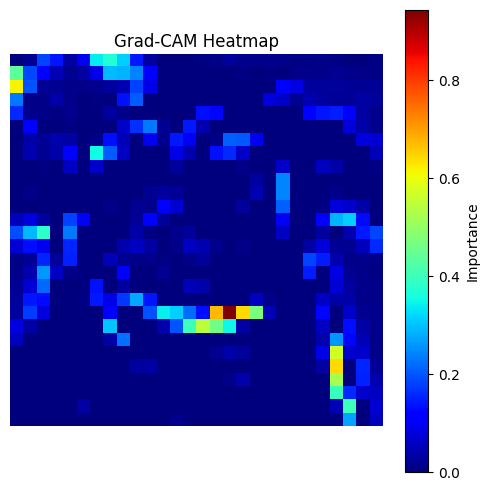

In [45]:
plt.figure(figsize=(6, 6))

plt.imshow(heatmap.numpy(), cmap="jet")
plt.colorbar(label="Importance")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.show()

### Step 8.7: Overlay Grad-CAM Heatmap on the Original Image

In this step, we resize the heatmap to match the original image dimensions and overlay it on the input image.

This visualization helps us understand which parts of the image influenced the CNN's prediction and whether the model is focusing on the actual object or the background.

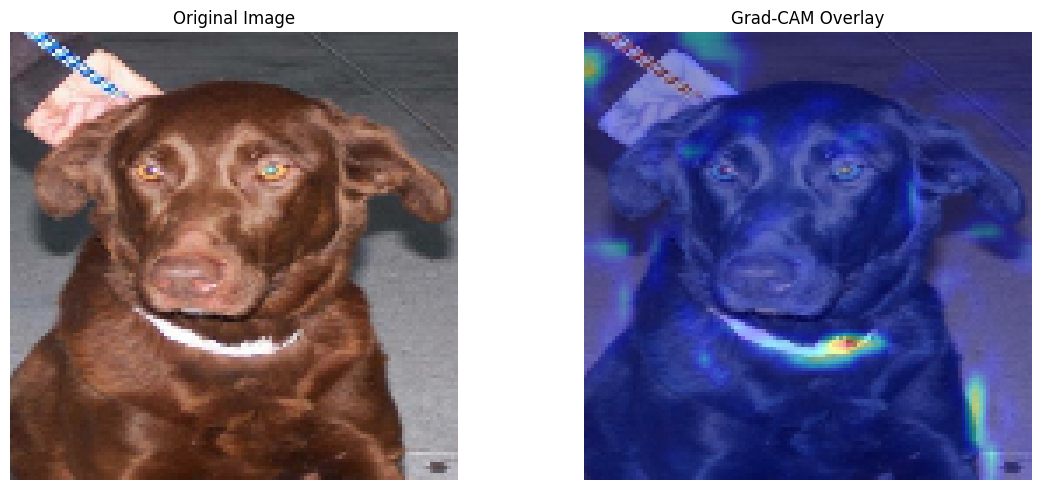

In [46]:
import cv2
import numpy as np

# Convert heatmap to an image and resize it
heatmap_resized = cv2.resize(
    heatmap.numpy(),
    (IMG_SIZE[1], IMG_SIZE[0])
)

# Convert heatmap values to 8-bit format
heatmap_uint8 = np.uint8(255 * heatmap_resized)

# Apply a color map
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)

# Convert original image to 8-bit format
original_image = np.uint8(
    sample_image.numpy() * 255
)

# Overlay heatmap on original image
superimposed_image = cv2.addWeighted(
    original_image, 0.6,
    heatmap_colored, 0.4, 0
)

# Display original image and Grad-CAM overlay
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(superimposed_image, cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

## Conclusion

In this experiment, a Convolutional Neural Network (CNN) was developed and trained to classify images of cats and dogs. The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

Grad-CAM was then applied to understand the regions of the input image that influenced the model's prediction. The heatmap and its overlay showed that the model focused strongly on the dog's collar and other background features rather than primarily focusing on its face or body.

This demonstrates how Grad-CAM helps interpret CNN predictions and identify potential shortcut learning. It also highlights the importance of training models on diverse and representative datasets so that they learn meaningful features rather than relying on irrelevant visual patterns.

### Observation of Training and Validation Performance

The training accuracy increased steadily, while the validation accuracy remained comparatively lower. Similarly, the training loss decreased, but the validation loss fluctuated and increased during training.

This indicates that the CNN model experienced overfitting. The model learned the training images effectively but did not generalize equally well to unseen validation images.

Possible improvements include using data augmentation, dropout, early stopping, and collecting more diverse training images.

Although the model did not achieve ideal validation performance, the experiment successfully demonstrates the CNN classification process and the importance of evaluating model generalization.

## Improving the model 

### Experiment 2 – Data Augmentation

Data augmentation artificially increases the variety of training images by applying random transformations.

We will use:
- Random horizontal flipping
- Random rotation
- Random zooming

These transformations help the CNN learn different variations of cats and dogs instead of memorizing the original training images.

In [47]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


### Improved CNN Model with Dropout

In this step, we build a new CNN model using the same architecture as the original model, but introduce data augmentation and dropout.

Dropout randomly deactivates a fraction of neurons during training. This helps prevent the model from relying too heavily on specific neurons and reduces overfitting.

In [48]:
improved_model = tf.keras.Sequential([
    tf.keras.Input(shape=(128, 128, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Second convolution block
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Third convolution block
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

improved_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### Training the Improved CNN Model

The improved CNN model is trained using the augmented training images.

We use Early Stopping to monitor validation loss. If the validation loss does not improve for 3 consecutive epochs, training will stop automatically. This helps reduce unnecessary training and overfitting.

In [49]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

EPOCHS_IMPROVED = 20

improved_history = improved_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_IMPROVED,
    callbacks=[early_stopping]
)

Epoch 1/20


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - accuracy: 0.4975 - loss: 0.6986 - val_accuracy: 0.5000 - val_loss: 0.6963
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - accuracy: 0.5465 - loss: 0.6884 - val_accuracy: 0.5520 - val_loss: 0.6666
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.5915 - loss: 0.6682 - val_accuracy: 0.6590 - val_loss: 0.6152
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - accuracy: 0.6110 - loss: 0.6463 - val_accuracy: 0.5730 - val_loss: 0.6473
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 116ms/step - accuracy: 0.6565 - loss: 0.6204 - val_accuracy: 0.7060 - val_loss: 0.5876
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - accuracy: 0.6840 - loss: 0.5923 - val_accuracy: 0.7060 - val_loss: 0.5875
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.6905 - loss: 0.5921 - val_accuracy: 0.6630 - val_loss: 0.6193
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.7035 - loss: 0.5772 - val_accuracy: 0.6670 - val_

### Improved Model: Training and Validation Performance

We plot the training and validation accuracy and loss of the improved CNN model.

These graphs help us understand whether data augmentation and dropout improved the model's ability to generalize to unseen images.

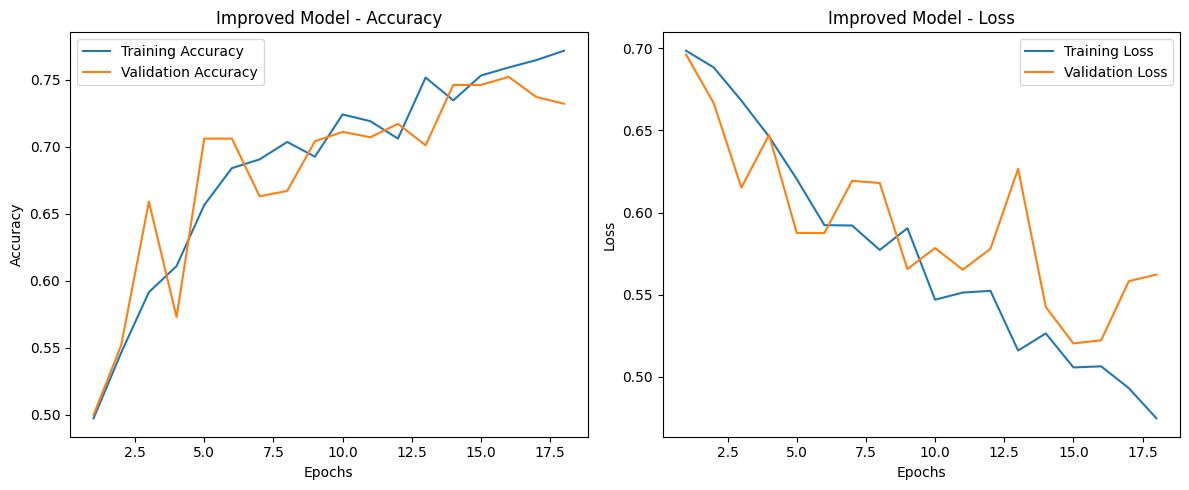

In [50]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(improved_history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, improved_history.history["accuracy"],
         label="Training Accuracy")
plt.plot(epochs_range, improved_history.history["val_accuracy"],
         label="Validation Accuracy")
plt.title("Improved Model - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, improved_history.history["loss"],
         label="Training Loss")
plt.plot(epochs_range, improved_history.history["val_loss"],
         label="Validation Loss")
plt.title("Improved Model - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()